# Part II — Questions 6–8: k-nearest neighbours

**Working template: no solutions implemented.**

Scope: the Question 6 hypothesis visualisation, Question 7 Protocol A and explanation, and Question 8 Protocol B and explanation, following the supplied brief (Sections 2.1.1–2.1.4).


## Setup

Add the imports and random seed used below. This notebook should run independently from a fresh kernel.

The shared `knn_predict` helper below uses Euclidean distance and is available to Questions 6–8.


In [63]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

### Helper Function of KNN Implementation

In [64]:
# Implementation of the KNN algorithm (In this coursework we set up k=3 or with course def v=3)
def knn_predict(centres, labels, query_point, k=3, verbose=True):
    """
    Inputs:
    - centres: A 2D numpy array of shape (n_centres, n_features) representing the coordinates of the centres.
    - labels: A 1D numpy array of shape (n_centres,) representing the labels associated with each centre.
    - query_point: A 1D numpy array of shape (n_features,) representing the coordinates of the query point.
    - k: An integer representing the number of nearest neighbours to consider (default is 3).
    - verbose: A boolean indicating whether to print debug information (default is True).
    
    Output:
    - The predicted label for the query point based on the majority vote of the k nearest neighbours
    - If the votes are tied, sample the predicted label uniformly at random from {0, 1}.
    """
    
    # Calculate the Euclidean distances from the query point to all centres
    # Using numpy's broadcasting and vectorization to compute distances efficiently
    distances = np.linalg.norm(centres - query_point, axis=1) # 'axis=1' computes the norm along rows
                                                                        # (i.e., for each centre)
    if verbose:
        print(f"Distances from query point {query_point} to centres: {distances}")
    
    # Get the indices of the k nearest neighbours
    nearest_indices = np.argsort(distances)[:k] 
    if verbose:
        print(f"Indices of the {k} nearest neighbours: {nearest_indices}")

    # Get the labels of the k nearest neighbours
    nearest_labels = labels[nearest_indices]
    if verbose:
        print(f"Labels of the {k} nearest neighbours: {nearest_labels}")

    # Get the most common label among the nearest neighbours without numpy's bincount
    vote = {}
    for label in nearest_labels:
        if label in vote:
            vote[label] += 1
        else:
            vote[label] = 1
    if verbose:
        print(f"Votes for each label: {vote}")

    # If the votes are tied, sample the predicted label uniformly at random from {0, 1}.
    if vote.get(0, 0) == vote.get(1, 0):
        predicted_label = np.random.randint(0, 2)
        if verbose:
            print(f"Tied votes: sampled label {predicted_label} uniformly at random from {{0, 1}}")
        return predicted_label

    return max(vote, key=vote.get)  # Return the label with the highest vote

## Question 6 — Generate and evaluate a voted-centre hypothesis

Sample 100 centres independently and uniformly from [0,1]^2, with independent labels sampled uniformly from {0,1}. Set v=3.

Define h(x) as the majority label among the three nearest centres. This nearest-centre calculation is needed to colour the plot in Question 6. Resolve undefined results by sampling a label uniformly from {0,1}, as required by Section 2.1.4. State the distance used.


In [65]:
# Step 1: Sample 5 centres, each with two independent uniform coordinates.
# First parameter is the lower bound (inclusive), second parameter is the upper bound (exclusive),
# Third parameter is the size of the output array that we want,
# in this case 5 rows of two columns each one,
# i.e. 5 centres in 2D space or 5 tuples.
centres = np.random.uniform(0, 1, size=(5, 2)) 

# Step 2: Sample 5 independent, equally likely binary labels for each centre.
# First parameter is the lower bound (inclusive), the second parameter is the upper bound (exclusive),
# Third parameter is the size of the output array that we want,
# in this case 5 rows, of one column each one, i.e. 5 labels.
labels = np.random.randint(0, 2, size=5) 

# labels[i] is the label associated with centres[i].

for i in range(5):
    # First 5 examples to see all is correct.
    print(f"Centre: {centres[i]}, Label: {labels[i]}")


Centre: [0.99000097 0.08527548], Label: 0
Centre: [0.89267265 0.2415108 ], Label: 0
Centre: [0.07866562 0.95602858], Label: 0
Centre: [0.62651695 0.52636079], Label: 1
Centre: [0.86318777 0.8050297 ], Label: 0


In [66]:
# Toy example to test the shared KNN implementation
query_point = np.array([0.7, 0.65])
k = 3
predicted_label = knn_predict(centres, labels, query_point, k)
print(f"Predicted label for query point {query_point} with k={k}: {predicted_label}")

Distances from query point [0.7  0.65] to centres: [0.63483411 0.45164829 0.69261093 0.14382772 0.22508766]
Indices of the 3 nearest neighbours: [3 4 1]
Labels of the 3 nearest neighbours: [1 0 0]
Votes for each label: {np.int64(1): 1, np.int64(0): 2}
Predicted label for query point [0.7  0.65] with k=3: 0


### Question 6 — Plot the hypothesis

Produce a visualisation of h similar to Figure 1: evaluate h on a grid over [0,1]^2, colour the regions for labels 0 and 1, and superimpose the 100 labelled centres. Use distinguishable colours and equal axis scaling.


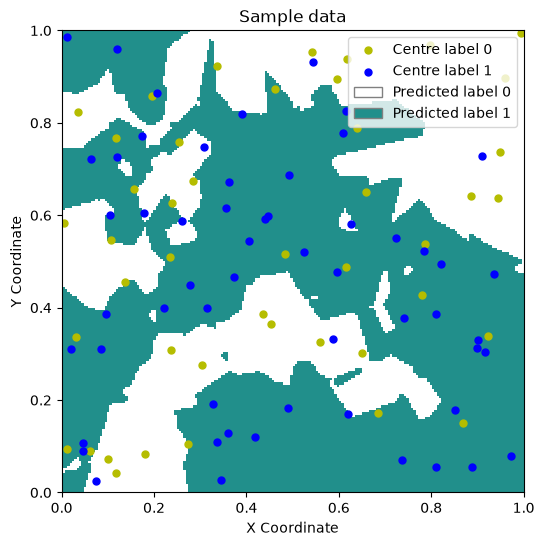

In [67]:
from matplotlib.patches import Patch

# 0. Create a 100 x 2 array of centres and a 1D array of 100 labels.
h_centres = np.random.uniform(0, 1, size=(100, 2))
h_labels = np.random.randint(0, 2, size=100)

# 1. Create a 200 x 200 grid over [0, 1]^2.
temporal_grid = np.linspace(0, 1, 200) # first param is the lower bound, second param is the upper bound,
                                       # third param is the number of points
                                       # Both endpoints are included; shape is (200,).
# For example if we had temporal_grid = np.linspace(0, 1, 3), we would get the following array:
# array([0. , 0.5, 1. ])
                                       
xx, yy = np.meshgrid(temporal_grid, temporal_grid) # first param is the x-coordinates, second param is the
                                               # y-coordinates
# Continuing the example, np.meshgrid(temporal_grid, temporal_grid) would give us the following two 2D arrays:
# xx = array([[0. , 0.5, 1.  ],
#              [0. , 0.5, 1.  ],
#              [0. , 0.5, 1.  ]])
# yy = array([[0. , 0. , 0.  ],
#              [0.5, 0.5, 0.5],
#              [1. , 1. , 1.  ]])
   
grid_points = np.column_stack((xx.ravel(), yy.ravel())) # .ravel() flattens the 2D arrays into 1D arrays,
                                                      # and np.column_stack combines them into a 2D array of shape (40000, 2).
# Following the example, .ravel() would give us:
# xx.ravel() = array([0. , 0.5, 1. , 0. , 0.5, 1. , 0. , 0.5, 1. ])
# yy.ravel() = array([0. , 0. , 0. , 0.5, 0.5, 0.5, 1. , 1. , 1. ])
# And np.column_stack would give us:
# grid_points = array([[0. , 0. ],
#                      [0.5, 0. ],
#                      [1. , 0. ],
#                      [0. , 0.5],
#                      [0.5, 0.5],
#                      [1. , 0.5],
#                      [0. , 1. ],
#                      [0.5, 1. ],
#                      [1. , 1. ]])

# 2. Predict each grid point using the three nearest centres.
predictions = []
for point in grid_points:
    # Silence debug output while evaluating all 40,000 grid points.
    predicted_label = knn_predict(h_centres, h_labels, point, 3, verbose=False)
    predictions.append(predicted_label)

# 3. Arrange the predictions to match the grid.
# Previously, we flattened the grid into a 1D array to make predictions. 
# Now, we need to reshape the predictions back into a 2D array of shape (200, 200) to match the original grid shape.
# For our example, prediction_grid would look like this:
# prediction_grid = array([[0, 0, 1],
#                          [0, 1, 1],
#                          [1, 1, 1]]) 
# Assuming the predictions were made in the order of the flattened grid points.
prediction_grid = np.array(predictions).reshape(xx.shape)

# 4. Draw the background: white for 0, turquoise for 1.
background_colours = ListedColormap(["white", "#218f8b"])
plt.figure(figsize=(6, 6))
plt.pcolormesh(
    xx, yy, prediction_grid,
    cmap=background_colours,
    vmin=0,
    vmax=1,
    shading="nearest"
)

# 5. Draw the labelled centres on top of the prediction regions.
plt.scatter(
    h_centres[h_labels == 0, 0], h_centres[h_labels == 0, 1],
    color="#b5bd00", label="Centre label 0", s=25
)
plt.scatter(
    h_centres[h_labels == 1, 0], h_centres[h_labels == 1, 1],
    color="blue", label="Centre label 1", s=25
)
plt.title("Sample data")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.gca().set_aspect("equal")
# Explain both the centre markers and the background prediction colours.
handles, _ = plt.gca().get_legend_handles_labels()
handles.extend([
    Patch(facecolor=background_colours(0), edgecolor="grey", label="Predicted label 0"),
    Patch(facecolor=background_colours(1), edgecolor="grey", label="Predicted label 1"),
])
plt.legend(handles=handles)
plt.show()


## Questions 7–8 — Noisy data and k-NN

Reuse the shared `knn_predict` helper defined after the imports for the experiments below. Resolve undefined predictions, including tied binary votes, uniformly at random as required by Section 2.1.4.

For a given h, sample each input x uniformly from [0,1]^2. With probability 0.8 use y=h(x); otherwise sample y uniformly from {0,1}. Generate both training and test examples this way. The 0.2 branch samples a fresh random label, so it can agree with h(x); it does not always flip the label.


## Question 7(a) — Protocol A

For each run of `experimental_protocol_A`:

1. **`p_H` generates one hypothesis `h`** by sampling 100 centres uniformly from `[0, 1]^2` and their labels uniformly from `{0, 1}`.
2. **`h(x)` returns the majority label of the 3 nearest centres** to `x`. It does not flip a coin.
3. **`p_h` generates a labelled example `(x, y)`** by sampling `x` uniformly from `[0, 1]^2` and flipping the biased coin: heads (0.8) sets `y = h(x)` using the existing 100 centres; tails (0.2) chooses `y` uniformly from `{0, 1}`.

The 4,000 training and 1,000 test examples both come from `p_h`, using the **same fixed `h` within a run**. Sample a fresh `h` from `p_H` for the next run. The evaluated k-NN model uses the 4,000 training examples and the current `k`; `h(x)` always uses 3 neighbours.

Follow Figure 2 with this loop order:

```text
for each k in {1,...,49}:
    for each of 100 runs:
        sample a fresh hypothesis h from p_H
        sample 4000 training examples from p_h(x,y)
        sample 1000 independent test examples from p_h(x,y)
        predict the test labels using k-NN on the training examples
        record the fraction of incorrect test predictions
    average the 100 run errors for this k
```

Plot k on the horizontal axis and its mean estimated generalisation error on the vertical axis.


In [68]:
def sample_hypothesis():
    """Sample a fresh hypothesis h from p_H, using the procedure from point 6."""
    # h_centres and h_labels are the centres and labels defining h
    h_centres = np.random.uniform(0, 1, size=(100, 2))
    h_labels = np.random.randint(0, 2, size=100)
    return h_centres, h_labels


In [69]:
def sample_noisy_data(h_centres, h_labels, n_samples):
    """Generate training or test examples from the same distribution p_h(x, y)."""
    # Get the input x of each sample (a point with two coordinates)
    # by sampling an x uniformly at random from [0, 1]**2.
    sample_centres = np.random.uniform(0, 1, size=(n_samples, 2))
    sample_labels = np.zeros(n_samples, dtype=int)  # Initialize labels array with zeros

    # Get the y label of each sample
    # by applying the rule of the biased coin to each input x,
    # i.e. by sampling a label from a Bernoulli distribution with
    # -> p=0.8 if it lands on heads, then the y label is h(x),
    #    calculated with knn_predict(h_centres, h_labels, x, k=3).
    # Note: h_centres and h_labels are generated as in the previous part
    # of the coursework (point 6), with a fresh hypothesis for each run.
    # -> p=0.2 if it lands on tails, then the y label is sampled uniformly random from {0, 1}.
    values_of_biased_coin = np.random.binomial(1, 0.8, size=n_samples) # first parameter is the number of trials,
                                                                  # second parameter is the probability of success,
                                                                  # in our case because we have a biased coin with
                                                                  # probability of heads = 0.8, we set the second
                                                                  # parameter to 0.8
    for sample in range(n_samples):
        if values_of_biased_coin[sample] == 1:
            sample_labels[sample] = knn_predict(
                h_centres, h_labels, sample_centres[sample], k=3, verbose=False
            )
        else:
            # If the biased coin lands on tails, then the y label is sampled uniformly random from {0, 1}.
            sample_labels[sample] = np.random.randint(0, 2)

    return sample_centres, sample_labels


In [70]:
def estimate_generalisation_error(training_centres_of_protocol_A, training_labels_of_protocol_A,
                                   test_centres_of_protocol_A, test_labels_of_protocol_A, k):
    """Predict each test point using the training examples and return the error fraction."""
    # For k-NN, training consists of storing the training points and their labels.
    # knn_predict accepts one query point at a time.
    predictions = []
    for point in test_centres_of_protocol_A:
        # Silence debug output while evaluating all test points.
        predicted_label = knn_predict(training_centres_of_protocol_A, training_labels_of_protocol_A, point, k=k, verbose=False)
        predictions.append(predicted_label)

    # Estimated generalisation error of the trained model on the test samples.
    return np.mean(test_labels_of_protocol_A != predictions)


In [71]:
def run_protocol_A(k, n_train=4000, n_test=1000):
    """Run one experiment with a fresh hypothesis h and independent training and test sets."""
    h_centres, h_labels = sample_hypothesis()
    training_centres_of_protocol_A, training_labels_of_protocol_A = sample_noisy_data(h_centres, h_labels, n_train)

    # Test the trained model on 1000 new samples, generated in the same way as the training samples.
    # Both sets use the same h_centres and h_labels to generate their labels.
    test_centres_of_protocol_A, test_labels_of_protocol_A = sample_noisy_data(h_centres, h_labels, n_test)
    return estimate_generalisation_error(
        training_centres_of_protocol_A, training_labels_of_protocol_A, test_centres_of_protocol_A, test_labels_of_protocol_A, k
    )


In [72]:
def experimental_protocol_A(verbose=False, k_values=range(1, 50), n_runs=100, n_train=4000, n_test=1000):
    """Return one mean error per k; defaults follow Protocol A in Figure 2.

    Each run samples h from p_H (100 centres and their labels).
    h(x) is the majority label of its 3 nearest centres, with no coin flip.
    p_h generates (x, y): sample x uniformly; with probability 0.8 use
    y = h(x), otherwise sample y uniformly from {0, 1}.
    Both training and test examples use the same h within each run.
    """
    average_generalisation_errors = []

    # Iterate over different values of k (from 1 to 49)
    # range(1, 50): lower bound is inclusive, upper bound is exclusive.
    for k in k_values:
        generalisation_errors = []  # Store the generalisation errors for each run

        # Perform 100 runs of the experiment for each value of k
        for run in range(n_runs):
            estimated_generalisation_error = run_protocol_A(k, n_train, n_test)
            generalisation_errors.append(estimated_generalisation_error)

        # Calculate the average generalisation error for the current value of k
        average_generalisation_error = np.mean(generalisation_errors)
        average_generalisation_errors.append(average_generalisation_error)
        if verbose:
            print(f"Average generalisation error for k={k}: {average_generalisation_error}")

    return np.array(average_generalisation_errors)


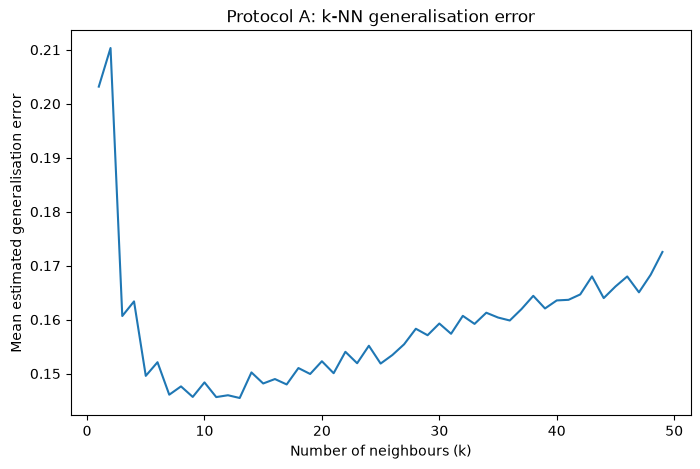

In [73]:
# Plot the average generalisation error as a function of k
k_values = range(1, 50)
average_generalisation_errors = experimental_protocol_A(verbose=False, k_values=k_values)

plt.figure(figsize=(8, 5))
plt.plot(k_values, average_generalisation_errors)
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean estimated generalisation error")
plt.title("Protocol A: k-NN generalisation error")
plt.show()


## Question 7(b) — Explain the observed curve

In roughly five sentences, explain the approximate shape of the resulting figure and comment on any interesting features.

Initially, the estimated generalisation error decreases as the number of neighbours, `k`, increases, because predictions become less sensitive to individual noisy labels. Considering more nearby points captures the local pattern more reliably than relying on only one or two neighbours. However, when `k` becomes too large, the estimated generalisation error starts to increase again because more distant points from regions with different labels influence the prediction. This smooths over local boundaries and small regions of `h`, reducing accuracy. The curve therefore reflects a balance between reducing the effect of noise and preserving local structure, with the lowest observed error around `k = 10` and small fluctuations due to random sampling.


## Question 8(a) — Protocol B

Follow Figure 3 with this loop order:

```text
for each m in {100,500,1000,1500,2000,2500,3000,3500,4000}:
    for each of 100 runs:
        for each k in {1,...,49}:
            sample a fresh hypothesis h
            sample m training examples from p_h(x,y)
            sample 1000 independent test examples from p_h(x,y)
            record the k-NN test error
        select the k with the smallest error in this run
    average the 100 selected k values for this m
```

Plot m on the horizontal axis and the mean selected k on the vertical axis. Record how equally minimal errors are handled. The hypothesis and data are sampled inside the k loop, as shown in Figure 3. Average the run-level selected k values; do not select k by minimising an error curve averaged across runs.


In [74]:
def experimental_protocol_B(verbose=False, n_runs=100, k_values=range(1, 50),
                            possible_data_set_sizes=(100, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000),
                            n_test=1000):
    """Average the per-run optimal k for each m, following Figure 3.

    Sample a fresh h and fresh training/test sets for each k within each run.
    If several k values have the same lowest error, select the smallest k.
    """
    k_values = sorted(k_values)
    results = {}
    for m in possible_data_set_sizes:
        best_k_values = []
        best_test_errors = []
        for run in range(n_runs):
            best_k = None
            lowest_error = float('inf')
            for k in k_values:
                # Sample a fresh hypothesis h from p_H, using the procedure from point 6.
                h_centres, h_labels = sample_hypothesis()
                # Sample m training examples from p_h(x, y) using the same h.
                training_centres_of_protocol_B, training_labels_of_protocol_B = sample_noisy_data(h_centres, h_labels, m)
                # Sample 1000 test examples from p_h(x, y) using the same h.
                test_centres_of_protocol_B, test_labels_of_protocol_B = sample_noisy_data(h_centres, h_labels, n_test)
                # Record the k-NN test error for this run, for this value of k, and for this value of m.
                estimated_generalisation_error = estimate_generalisation_error(
                    training_centres_of_protocol_B, training_labels_of_protocol_B,
                    test_centres_of_protocol_B, test_labels_of_protocol_B, k
                )
                if estimated_generalisation_error < lowest_error:
                    lowest_error = estimated_generalisation_error
                    best_k = k
            # Select the k with the lowest test error for this run
            # Keep every run, including repeated selections of the same k.
            best_k_values.append(best_k)
            best_test_errors.append(lowest_error)
        # Average the 100 selected k's for this value of m, and report the average selected k
        # and the average test error for this value of m.
        average_best_k = np.mean(best_k_values)
        average_test_error = np.mean(best_test_errors)
        if verbose:
            print(f"Data set size: {m}, Average best k: {average_best_k}, Average test error: {average_test_error}")
        # Save the results for each data set size m
        results[m] = {
            'average_best_k': average_best_k,
            'average_test_error': average_test_error
        }
    return results


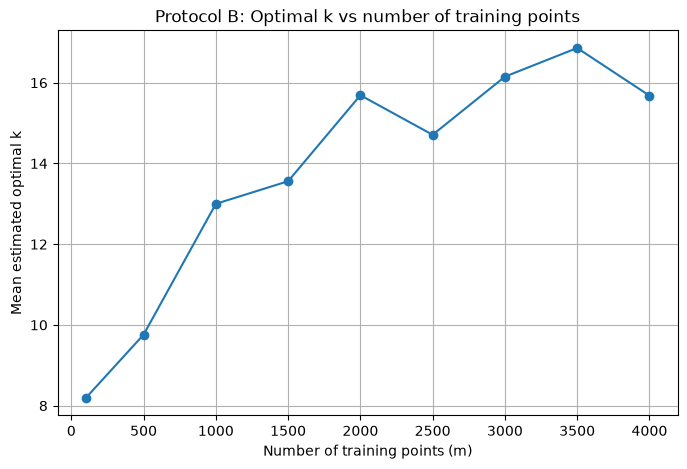

In [75]:
# Plot m versus optimal k
results = experimental_protocol_B()
data_set_sizes = sorted(results.keys())
average_best_k_values = [results[m]['average_best_k'] for m in data_set_sizes]

plt.figure(figsize=(8, 5))
plt.plot(data_set_sizes, average_best_k_values, marker='o')
plt.xlabel("Number of training points (m)")
plt.ylabel("Mean estimated optimal k")
plt.title("Protocol B: Optimal k vs number of training points")
plt.grid()
plt.show() 

## Question 8(b) — Explain the observed relationship

In roughly four sentences, explain the approximate shape of the resulting figure relating m to the estimated optimal k.

With fewer training points, the data are sparse, so a smaller `k` avoids including distant neighbours from regions with different labels. As the number of training points `m` increases, the data become denser, allowing more nearby neighbours to contribute while remaining within the same region and reducing sensitivity to noisy labels. The estimated optimal `k` increases only from approximately 8 to 16, doubling while the training-set size grows fortyfold from 100 to 4,000. The overall upward trend is therefore reasonable, while the small decreases can be attributed to variability in the randomly generated hypotheses and datasets.
